# Sales Analysis: AAL Apparel, Q4 2020 (Australia)
**Course-End Project: Applied Data Science with Python**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100
print("pandas", pd.__version__, "| numpy", np.__version__, "| seaborn", sns.__version__)

pandas 3.0.6 | numpy 2.5.4 | seaborn 0.13.2


# Step 1: Data Wrangling
## 1a. Inspect the data for missing or incorrect entries

In [ ]:
df = pd.read_csv("AusApparalSales4thQrt2020.csv")
df.head(10)

,Date,Time,State,Group,Unit,Sales
0,1-Oct-2020,Morning,WA,Kids,8,20000
1,1-Oct-2020,Morning,WA,Men,8,20000
2,1-Oct-2020,Morning,WA,Women,4,10000
3,1-Oct-2020,Morning,WA,Seniors,15,37500
4,1-Oct-2020,Afternoon,WA,Kids,3,7500
5,1-Oct-2020,Afternoon,WA,Men,10,25000
6,1-Oct-2020,Afternoon,WA,Women,3,7500
7,1-Oct-2020,Afternoon,WA,Seniors,11,27500
8,1-Oct-2020,Evening,WA,Kids,15,37500
9,1-Oct-2020,Evening,WA,Men,15,37500


In [ ]:
print("Shape:", df.shape)
print()
df.info()

Shape: (7560, 6)

<class 'pandas.DataFrame'>
RangeIndex: 7560 entries, 0 to 7559
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Date    7560 non-null   str  
 1   Time    7560 non-null   str  
 2   State   7560 non-null   str  
 3   Group   7560 non-null   str  
 4   Unit    7560 non-null   int64
 5   Sales   7560 non-null   int64
dtypes: int64(2), str(4)
memory usage: 354.5 KB


In [ ]:
# Missing values, using isna() and notna()
print("Missing values per column (isna):")
print(df.isna().sum())
print("\nNon-missing values per column (notna):")
print(df.notna().sum())
print("\nTotal missing cells        :", df.isna().sum().sum())
print("Rows with any missing value:", df.isna().any(axis=1).sum())
print("Fully populated rows       :", df.notna().all(axis=1).sum(), "of", len(df))

Missing values per column (isna):
Date     0
Time     0
State    0
Group    0
Unit     0
Sales    0
dtype: int64

Non-missing values per column (notna):
Date     7560
Time     7560
State    7560
Group    7560
Unit     7560
Sales    7560
dtype: int64

Total missing cells        : 0
Rows with any missing value: 0
Fully populated rows       : 7560 of 7560


In [ ]:
# Incorrect entries: stray spaces, inconsistent labels, impossible values, duplicates
for col in ["Time", "State", "Group"]:
    print(f"{col:<6} unique values (raw):", df[col].unique().tolist())

print("\nValues with leading/trailing spaces:",
      {col: int((df[col] != df[col].str.strip()).sum()) for col in ["Time", "State", "Group"]})
print("Date column dtype:", df["Date"].dtype, "(text, should be a datetime)")
print("Unit <= 0 :", (df["Unit"] <= 0).sum())
print("Sales <= 0:", (df["Sales"] <= 0).sum())
print("Duplicate rows:", df.duplicated().sum())

Time   unique values (raw): [' Morning', ' Afternoon', ' Evening']
State  unique values (raw): [' WA', ' NT', ' SA', ' VIC', ' QLD', ' NSW', ' TAS']
Group  unique values (raw): [' Kids', ' Men', ' Women', ' Seniors']

Values with leading/trailing spaces: {'Time': 7560, 'State': 7560, 'Group': 7560}
Date column dtype: str (text, should be a datetime)
Unit <= 0 : 0
Sales <= 0: 0
Duplicate rows: 0


In [ ]:
# Fix the incorrect entries: strip spaces and parse dates
for col in ["Time", "State", "Group"]:
    df[col] = df[col].str.strip()
df["Date"] = pd.to_datetime(df["Date"], format="%d-%b-%Y")

print("Date range  :", df["Date"].min().date(), "to", df["Date"].max().date())
print("Unique days :", df["Date"].nunique())
print("Rows per day:", df.groupby("Date").size().unique(), "(7 states x 4 groups x 3 time slots = 84)")
print("States      :", sorted(df["State"].unique()))
print("Groups      :", sorted(df["Group"].unique()))
print("Time slots  :", df["Time"].unique().tolist())

# Are there gaps in the calendar?
full_range = pd.date_range("2020-10-01", "2020-12-31")
missing_days = sorted(set(full_range) - set(df["Date"]))
print("\nCalendar days in Q4 2020:", len(full_range))
print("Days missing from file  :", [d.strftime("%d-%b-%Y") for d in missing_days])

# Is Sales consistent with Unit?
price_per_unit = df["Sales"] / df["Unit"]
print("\nSales per unit  -> min:", price_per_unit.min(), "| max:", price_per_unit.max())

Date range  : 2020-10-01 to 2020-12-30
Unique days : 90
Rows per day: [84] (7 states x 4 groups x 3 time slots = 84)
States      : ['NSW', 'NT', 'QLD', 'SA', 'TAS', 'VIC', 'WA']
Groups      : ['Kids', 'Men', 'Seniors', 'Women']
Time slots  : ['Morning', 'Afternoon', 'Evening']

Calendar days in Q4 2020: 92
Days missing from file  : ['31-Oct-2020', '31-Dec-2020']

Sales per unit  -> min: 2500.0 | max: 2500.0


## 1b. Recommendations for treating missing and incorrect data

In [ ]:
# Recommendation: drop rows if nulls are few (<5%); otherwise fill with the State + Group median
# Demonstration on a COPY with injected nulls (the real data stays untouched)
demo = df.copy()
demo.loc[[0, 1, 2], "Sales"] = np.nan
demo.loc[[3, 4], "Unit"] = np.nan
print("Injected nulls:", demo.isna().sum().sum())

# Option 1: drop the rows
dropped = demo.dropna()
print("Option 1 (dropna)  -> rows left:", len(dropped), "of", len(demo))

# Option 2: fill with the median of the same State + Group
filled = demo.copy()
for col in ["Sales", "Unit"]:
    filled[col] = filled[col].fillna(filled.groupby(["State", "Group"])[col].transform("median"))
print("Option 2 (fillna)  -> nulls left:", filled.isna().sum().sum())
print(filled.loc[0:4, ["State", "Group", "Unit", "Sales"]])

Injected nulls: 5
Option 1 (dropna)  -> rows left: 7555 of 7560
Option 2 (fillna)  -> nulls left: 0
  State    Group  Unit    Sales
0    WA     Kids   8.0  20000.0
1    WA      Men   8.0  20000.0
2    WA    Women   4.0  17500.0
3    WA  Seniors   8.0  37500.0
4    WA     Kids   8.0   7500.0


In [ ]:
# Apply the cleaning rules to the real data
df_clean = df.dropna().drop_duplicates().reset_index(drop=True)
print("Rows before cleaning:", len(df), "| rows after cleaning:", len(df_clean))

Rows before cleaning: 7560 | rows after cleaning: 7560


## 1c. Data wrangling technique: Normalization (min-max scaling)

In [ ]:
# Min-max normalization (preferred): rescales to 0-1 and keeps the shape of the data
def min_max(s):
    return (s - s.min()) / (s.max() - s.min())

df_norm = df_clean.copy()
df_norm["Unit_norm"] = min_max(df_norm["Unit"])
df_norm["Sales_norm"] = min_max(df_norm["Sales"])

df_norm[["Date", "State", "Group", "Unit", "Sales", "Unit_norm", "Sales_norm"]].head(10)

,Date,State,Group,Unit,Sales,Unit_norm,Sales_norm
0,2020-10-01,WA,Kids,8,20000,0.095238,0.095238
1,2020-10-01,WA,Men,8,20000,0.095238,0.095238
2,2020-10-01,WA,Women,4,10000,0.031746,0.031746
3,2020-10-01,WA,Seniors,15,37500,0.206349,0.206349
4,2020-10-01,WA,Kids,3,7500,0.015873,0.015873
5,2020-10-01,WA,Men,10,25000,0.126984,0.126984
6,2020-10-01,WA,Women,3,7500,0.015873,0.015873
7,2020-10-01,WA,Seniors,11,27500,0.142857,0.142857
8,2020-10-01,WA,Kids,15,37500,0.206349,0.206349
9,2020-10-01,WA,Men,15,37500,0.206349,0.206349


In [ ]:
print(df_norm[["Unit_norm", "Sales_norm"]].describe().round(4))
print("\nUnit_norm and Sales_norm identical?", np.allclose(df_norm["Unit_norm"], df_norm["Sales_norm"]))

       Unit_norm  Sales_norm
count  7560.0000   7560.0000
mean      0.2541      0.2541
std       0.2048      0.2048
min       0.0000      0.0000
25%       0.0952      0.0952
50%       0.1905      0.1905
75%       0.3810      0.3810
max       1.0000      1.0000

Unit_norm and Sales_norm identical? True


## 1d. GroupBy(): data chunking and merging

In [ ]:
# CHUNKING: split the data into one chunk per State
for state, chunk in df_clean.groupby("State"):
    print(f"{state:<4} rows = {len(chunk):>4}   units = {chunk['Unit'].sum():>6,}   sales = {chunk['Sales'].sum():>12,}")

NSW  rows = 1080   units = 29,988   sales =   74,970,000
NT   rows = 1080   units =  9,032   sales =   22,580,000
QLD  rows = 1080   units = 13,367   sales =   33,417,500
SA   rows = 1080   units = 23,543   sales =   58,857,500
TAS  rows = 1080   units =  9,104   sales =   22,760,000
VIC  rows = 1080   units = 42,226   sales =  105,565,000
WA   rows = 1080   units =  8,861   sales =   22,152,500


In [ ]:
# AGGREGATE each chunk into a summary table
state_summary = (df_clean.groupby("State")
                 .agg(Total_Sales=("Sales", "sum"),
                      Total_Units=("Unit", "sum"),
                      Avg_Sale=("Sales", "mean"),
                      Transactions=("Sales", "count"))
                 .sort_values("Total_Sales", ascending=False))
state_summary["Share_%"] = (state_summary["Total_Sales"] / state_summary["Total_Sales"].sum() * 100).round(1)
state_summary

,Total_Sales,Total_Units,Avg_Sale,Transactions,Share_%
State,,,,,
VIC,105565000,42226,97745.370370,1080,31.0
NSW,74970000,29988,69416.666667,1080,22.0
SA,58857500,23543,54497.685185,1080,17.3
QLD,33417500,13367,30942.129630,1080,9.8
TAS,22760000,9104,21074.074074,1080,6.7
NT,22580000,9032,20907.407407,1080,6.6
WA,22152500,8861,20511.574074,1080,6.5


In [ ]:
# Recommendation: groupby().agg() for chunking/summaries; merge() or transform() to join group totals back to rows
# MERGING: bring the state totals back onto each row, then measure each row's share of its state
merged = df_clean.merge(state_summary[["Total_Sales"]].rename(columns={"Total_Sales": "State_Total"}),
                        left_on="State", right_index=True)
merged["Share_of_State_%"] = (merged["Sales"] / merged["State_Total"] * 100).round(4)
print(merged[["Date", "State", "Group", "Sales", "State_Total", "Share_of_State_%"]].head())

# Same result with transform(), without a separate merge
check = df_clean["Sales"] / df_clean.groupby("State")["Sales"].transform("sum") * 100
print("\ntransform() gives the same shares:", np.allclose(check.round(4), merged.sort_index()["Share_of_State_%"]))

        Date State    Group  Sales  State_Total  Share_of_State_%
0 2020-10-01    WA     Kids  20000     22152500            0.0903
1 2020-10-01    WA      Men  20000     22152500            0.0903
2 2020-10-01    WA    Women  10000     22152500            0.0451
3 2020-10-01    WA  Seniors  37500     22152500            0.1693
4 2020-10-01    WA     Kids   7500     22152500            0.0339

transform() gives the same shares: True


In [ ]:
# State x Group pivot (GroupBy on two keys)
pivot_sg = df_clean.pivot_table(index="State", columns="Group", values="Sales", aggfunc="sum")
pivot_sg["Total"] = pivot_sg.sum(axis=1)
pivot_sg.sort_values("Total", ascending=False)

Group,Kids,Men,Seniors,Women,Total
State,,,,,
VIC,26360000,26407500,26315000,26482500,105565000
NSW,18587500,19022500,18187500,19172500,74970000
SA,14515000,14655000,14717500,14970000,58857500
QLD,8510000,8392500,8190000,8325000,33417500
TAS,5775000,5757500,5650000,5577500,22760000
NT,5700000,5762500,5465000,5652500,22580000
WA,5625000,5752500,5512500,5262500,22152500


# Step 2: Data Analysis
## 2a. Descriptive statistics for `Sales` and `Unit`

In [ ]:
cols = ["Sales", "Unit"]
desc = pd.DataFrame({
    "Mean":     df_clean[cols].mean(),
    "Median":   df_clean[cols].median(),
    "Mode":     [stats.mode(df_clean[c], keepdims=False).mode for c in cols],
    "Std Dev":  df_clean[cols].std(),
    "Min":      df_clean[cols].min(),
    "Max":      df_clean[cols].max(),
    "Skewness": [stats.skew(df_clean[c]) for c in cols],
})
desc.round(2)

,Mean,Median,Mode,Std Dev,Min,Max,Skewness
Sales,45013.56,35000.0,22500,32253.51,5000,162500,1.09
Unit,18.01,14.0,9,12.90,2,65,1.09


Sales Q1=20,000  Q3=65,000  IQR=45,000  outliers=123 (1.6%)
Unit  Q1=8  Q3=26  IQR=18  outliers=123 (1.6%)


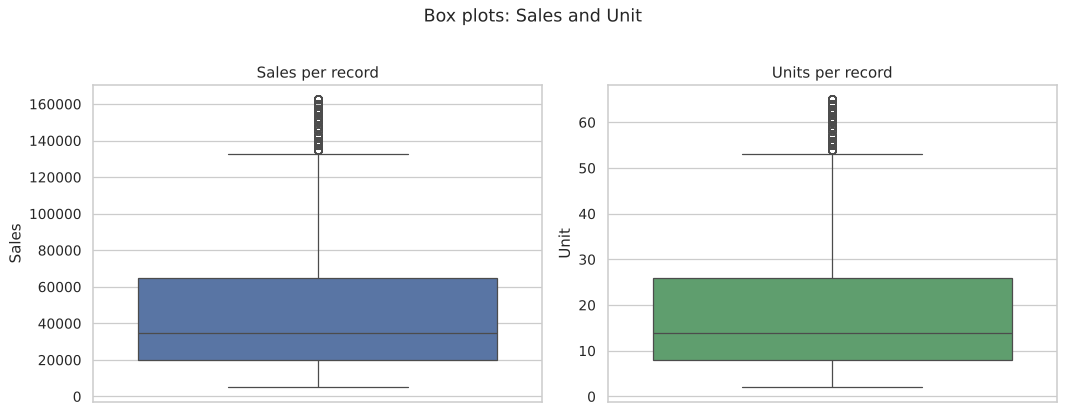

In [ ]:
# Box plots for the descriptive statistics
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(y=df_clean["Sales"], ax=axes[0], color="#4C72B0")
axes[0].set_title("Sales per record")
sns.boxplot(y=df_clean["Unit"], ax=axes[1], color="#55A868")
axes[1].set_title("Units per record")
plt.suptitle("Box plots: Sales and Unit", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# Outlier count using the 1.5 x IQR rule
for c in cols:
    q1, q3 = df_clean[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df_clean[c] < q1 - 1.5 * iqr) | (df_clean[c] > q3 + 1.5 * iqr)).sum()
    print(f"{c:<5} Q1={q1:,.0f}  Q3={q3:,.0f}  IQR={iqr:,.0f}  outliers={n_out} ({n_out/len(df_clean)*100:.1f}%)")

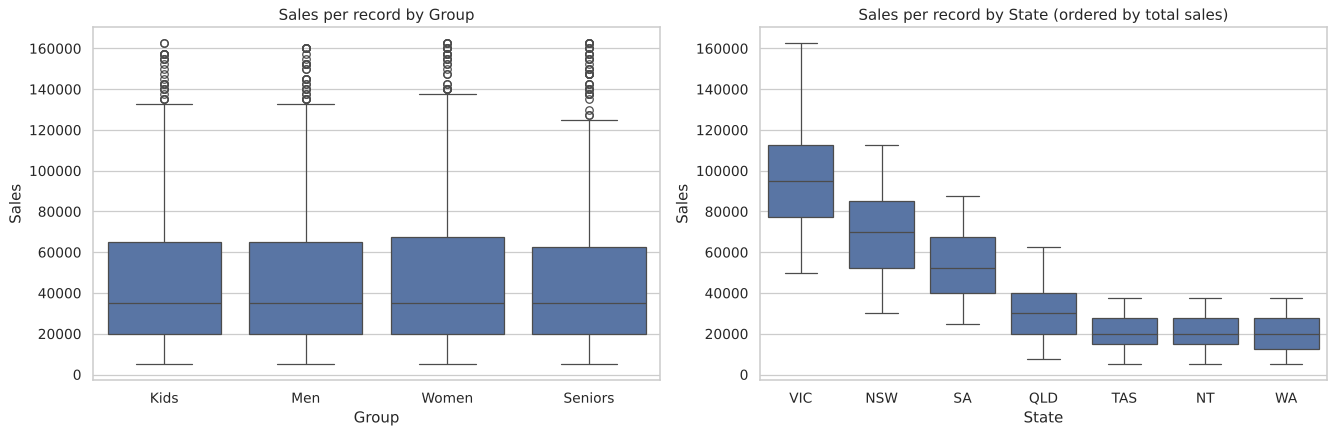

In [ ]:
# Box plots of Sales by Group and by State
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=df_clean, x="Group", y="Sales", ax=axes[0])
axes[0].set_title("Sales per record by Group")
order = df_clean.groupby("State")["Sales"].sum().sort_values(ascending=False).index
sns.boxplot(data=df_clean, x="State", y="Sales", order=order, ax=axes[1])
axes[1].set_title("Sales per record by State (ordered by total sales)")
plt.tight_layout()
plt.show()

## 2b. State with the highest and lowest sales

In [ ]:
state_sales = df_clean.groupby("State")["Sales"].sum().sort_values(ascending=False)
state_rank = pd.DataFrame({
    "Total_Sales": state_sales,
    "Share_%": (state_sales / state_sales.sum() * 100).round(1),
    "Cumulative_%": (state_sales.cumsum() / state_sales.sum() * 100).round(1),
})
state_rank.insert(0, "Rank", range(1, len(state_rank) + 1))
print("HIGHEST-selling state:", state_sales.idxmax(), f"(${state_sales.max():,})")
print("LOWEST-selling state :", state_sales.idxmin(), f"(${state_sales.min():,})")
state_rank

HIGHEST-selling state: VIC ($105,565,000)
LOWEST-selling state : WA ($22,152,500)


,Rank,Total_Sales,Share_%,Cumulative_%
State,,,,
VIC,1,105565000,31.0,31.0
NSW,2,74970000,22.0,53.1
SA,3,58857500,17.3,70.3
QLD,4,33417500,9.8,80.2
TAS,5,22760000,6.7,86.9
NT,6,22580000,6.6,93.5
WA,7,22152500,6.5,100.0


In [ ]:
# State x Group combinations: strongest and weakest
sg = df_clean.groupby(["State", "Group"])["Sales"].sum().sort_values(ascending=False)
print("Top 3 State-Group combinations:")
print(sg.head(3).map("${:,}".format))
print("\nBottom 3 State-Group combinations:")
print(sg.tail(3).map("${:,}".format))

# Strongest and weakest group inside each state
pivot = df_clean.pivot_table(index="State", columns="Group", values="Sales", aggfunc="sum").loc[state_sales.index]
pd.DataFrame({"Strongest_Group": pivot.idxmax(axis=1), "Weakest_Group": pivot.idxmin(axis=1),
              "Gap_%": ((pivot.max(axis=1) - pivot.min(axis=1)) / pivot.max(axis=1) * 100).round(1)})

Top 3 State-Group combinations:
State  Group
VIC    Women    $26,482,500
       Men      $26,407,500
       Kids     $26,360,000
Name: Sales, dtype: str

Bottom 3 State-Group combinations:
State  Group  
WA     Seniors    $5,512,500
NT     Seniors    $5,465,000
WA     Women      $5,262,500
Name: Sales, dtype: str


,Strongest_Group,Weakest_Group,Gap_%
State,,,
VIC,Women,Seniors,0.6
NSW,Women,Seniors,5.1
SA,Women,Kids,3.0
QLD,Kids,Seniors,3.8
TAS,Kids,Women,3.4
NT,Men,Seniors,5.2
WA,Men,Women,8.5


## 2c. Demographic group with the highest and lowest sales

In [ ]:
group_sales = df_clean.groupby("Group")["Sales"].sum().sort_values(ascending=False)
group_rank = pd.DataFrame({
    "Total_Sales": group_sales,
    "Total_Units": df_clean.groupby("Group")["Unit"].sum().reindex(group_sales.index),
    "Share_%": (group_sales / group_sales.sum() * 100).round(1),
})
print("HIGHEST-selling group:", group_sales.idxmax(), f"(${group_sales.max():,})")
print("LOWEST-selling group :", group_sales.idxmin(), f"(${group_sales.min():,})")
print(f"Gap between highest and lowest: {(group_sales.max()-group_sales.min())/group_sales.max()*100:.1f}%")
group_rank

HIGHEST-selling group: Men ($85,750,000)
LOWEST-selling group : Seniors ($84,037,500)
Gap between highest and lowest: 2.0%


,Total_Sales,Total_Units,Share_%
Group,,,
Men,85750000,34300,25.2
Women,85442500,34177,25.1
Kids,85072500,34029,25.0
Seniors,84037500,33615,24.7


In [ ]:
# Time-of-day: peak and off-peak periods
time_order = ["Morning", "Afternoon", "Evening"]
tod = df_clean.groupby("Time")["Sales"].agg(Total_Sales="sum", Avg_per_Record="mean").reindex(time_order)
tod["Share_%"] = (tod["Total_Sales"] / tod["Total_Sales"].sum() * 100).round(1)
print("PEAK period    :", tod["Total_Sales"].idxmax())
print("OFF-PEAK period:", tod["Total_Sales"].idxmin())
print(f"Gap between peak and off-peak: {(tod['Total_Sales'].max()-tod['Total_Sales'].min())/tod['Total_Sales'].max()*100:.1f}%")
tod

PEAK period    : Morning
OFF-PEAK period: Evening
Gap between peak and off-peak: 1.9%


,Total_Sales,Avg_per_Record,Share_%
Time,,,
Morning,114207500,45320.436508,33.6
Afternoon,114007500,45241.071429,33.5
Evening,112087500,44479.166667,32.9


In [ ]:
# Peak time slot for each State and each Group
time_state = df_clean.pivot_table(index="State", columns="Time", values="Sales", aggfunc="sum")[time_order]
time_group = df_clean.pivot_table(index="Group", columns="Time", values="Sales", aggfunc="sum")[time_order]
print("Peak time slot per State:\n", time_state.idxmax(axis=1).to_string())
print("\nPeak time slot per Group:\n", time_group.idxmax(axis=1).to_string())

Peak time slot per State:
 State
NSW      Morning
NT       Evening
QLD      Morning
SA     Afternoon
TAS    Afternoon
VIC      Morning
WA       Morning

Peak time slot per Group:
 Group
Kids         Morning
Men        Afternoon
Seniors      Morning
Women        Evening


## 2d. Weekly, monthly and quarterly reports

In [ ]:
# Helper columns for time-based reporting
df_clean["Month"] = df_clean["Date"].dt.month_name()
df_clean["Week"] = df_clean["Date"].dt.isocalendar().week.astype(int)
df_clean["Quarter"] = "Q" + df_clean["Date"].dt.quarter.astype(str) + " " + df_clean["Date"].dt.year.astype(str)
df_clean["DayName"] = df_clean["Date"].dt.day_name()

# DAILY summary
daily = df_clean.groupby("Date")["Sales"].sum()
print(f"Average daily sales : ${daily.mean():,.0f}")
print(f"Best day            : {daily.idxmax().date()} (${daily.max():,})")
print(f"Weakest day         : {daily.idxmin().date()} (${daily.min():,})")

Average daily sales : $3,781,139
Best day            : 2020-12-14 ($4,765,000)
Weakest day         : 2020-11-02 ($2,725,000)


In [ ]:
# WEEKLY report (ISO weeks, Monday to Sunday; the first and last weeks are partial)
weekly = (df_clean.groupby("Week")
          .agg(Week_Start=("Date", "min"), Week_End=("Date", "max"), Days=("Date", "nunique"),
               Total_Sales=("Sales", "sum"), Total_Units=("Unit", "sum")))
weekly["Avg_Daily_Sales"] = (weekly["Total_Sales"] / weekly["Days"]).round(0)
weekly

,Week_Start,Week_End,Days,Total_Sales,Total_Units,Avg_Daily_Sales
Week,,,,,,
40,2020-10-01,2020-10-04,4,15045000,6018,3761250.0
41,2020-10-05,2020-10-11,7,27002500,10801,3857500.0
42,2020-10-12,2020-10-18,7,26640000,10656,3805714.0
43,2020-10-19,2020-10-25,7,26815000,10726,3830714.0
44,2020-10-26,2020-11-01,6,21807500,8723,3634583.0
45,2020-11-02,2020-11-08,7,20865000,8346,2980714.0
46,2020-11-09,2020-11-15,7,21172500,8469,3024643.0
47,2020-11-16,2020-11-22,7,21112500,8445,3016071.0
48,2020-11-23,2020-11-29,7,21477500,8591,3068214.0


In [ ]:
# MONTHLY report
month_order = ["October", "November", "December"]
monthly = (df_clean.groupby("Month")
           .agg(Days=("Date", "nunique"), Total_Sales=("Sales", "sum"), Total_Units=("Unit", "sum"))
           .reindex(month_order))
monthly["Avg_Daily_Sales"] = (monthly["Total_Sales"] / monthly["Days"]).round(0)
monthly["MoM_Change_%"] = (monthly["Total_Sales"].pct_change() * 100).round(1)
monthly

,Days,Total_Sales,Total_Units,Avg_Daily_Sales,MoM_Change_%
Month,,,,,
October,30,114290000,45716,3809667.0,NaN
November,30,90682500,36273,3022750.0,-20.7
December,30,135330000,54132,4511000.0,49.2


In [ ]:
# Monthly sales by State
df_clean.pivot_table(index="State", columns="Month", values="Sales", aggfunc="sum")[month_order] \
        .assign(Total=lambda x: x.sum(axis=1)).sort_values("Total", ascending=False)

Month,October,November,December,Total
State,,,,
VIC,33442500,29530000,42592500,105565000
NSW,25007500,21490000,28472500,74970000
SA,20610000,15532500,22715000,58857500
QLD,11120000,8110000,14187500,33417500
TAS,8015000,5545000,9200000,22760000
NT,8222500,5257500,9100000,22580000
WA,7872500,5217500,9062500,22152500


In [ ]:
# QUARTERLY report (the file holds one quarter: Q4 2020)
quarterly = (df_clean.groupby("Quarter")
             .agg(Days=("Date", "nunique"), Total_Sales=("Sales", "sum"), Total_Units=("Unit", "sum")))
print(quarterly)

q_state = (df_clean.groupby("State")
           .agg(Q4_Sales=("Sales", "sum"), Q4_Units=("Unit", "sum"))
           .sort_values("Q4_Sales", ascending=False))
q_state["Share_%"] = (q_state["Q4_Sales"] / q_state["Q4_Sales"].sum() * 100).round(1)
q_state["Rank"] = range(1, len(q_state) + 1)
q_state

         Days  Total_Sales  Total_Units
Quarter                                
Q4 2020    90    340302500       136121


,Q4_Sales,Q4_Units,Share_%,Rank
State,,,,
VIC,105565000,42226,31.0,1
NSW,74970000,29988,22.0,2
SA,58857500,23543,17.3,3
QLD,33417500,13367,9.8,4
TAS,22760000,9104,6.7,5
NT,22580000,9032,6.6,6
WA,22152500,8861,6.5,7


In [ ]:
# Is the difference between groups statistically meaningful? One-way ANOVA on Sales per record
for factor in ["State", "Group", "Time"]:
    samples = [g["Sales"].values for _, g in df_clean.groupby(factor)]
    f_stat, p_val = stats.f_oneway(*samples)
    verdict = "significant difference" if p_val < 0.05 else "no significant difference"
    print(f"By {factor:<5}: F = {f_stat:8.2f}, p = {p_val:.4g}  ->  {verdict}")

By State: F =  3662.59, p = 0  ->  significant difference
By Group: F =     0.28, p = 0.838  ->  no significant difference
By Time : F =     0.52, p = 0.593  ->  no significant difference


# Step 3: Data Visualization (S&M Dashboard)

In [ ]:
# Recommended library: Seaborn (built for statistical plots and works directly with pandas DataFrames)
# Plot-ready tables (sales in $ millions)
plot_df = df_clean.groupby(["State", "Group"], as_index=False)["Sales"].sum()
plot_df["Sales_M"] = plot_df["Sales"] / 1e6
state_order = df_clean.groupby("State")["Sales"].sum().sort_values(ascending=False).index.tolist()
group_order = ["Kids", "Women", "Men", "Seniors"]
time_order = ["Morning", "Afternoon", "Evening"]

def label_bars(ax, fmt="{:.1f}", horizontal=False):
    """Write the value on top of (or beside) every drawn bar."""
    for p in ax.patches:
        if horizontal:
            v = p.get_width()
            if v > 0:
                ax.annotate(fmt.format(v), (v, p.get_y() + p.get_height() / 2), xytext=(3, 0),
                            textcoords="offset points", va="center", fontsize=9)
        else:
            v = p.get_height()
            if v > 0:
                ax.annotate(fmt.format(v), (p.get_x() + p.get_width() / 2, v), xytext=(0, 3),
                            textcoords="offset points", ha="center", fontsize=9)

## 3A. State-wise sales for each demographic group

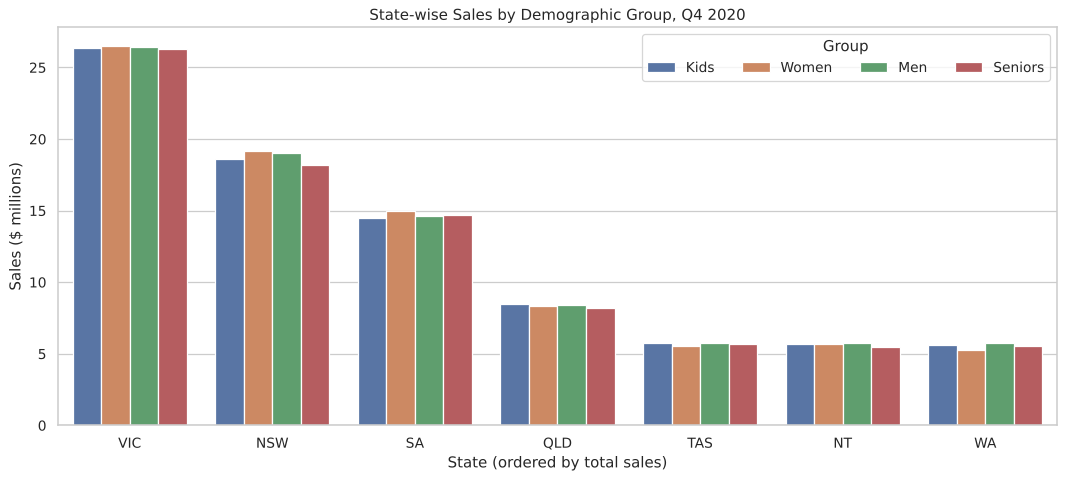

In [ ]:
plt.figure(figsize=(12, 5.5))
ax = sns.barplot(data=plot_df, x="State", y="Sales_M", hue="Group", order=state_order, hue_order=group_order)
ax.set(title="State-wise Sales by Demographic Group, Q4 2020", xlabel="State (ordered by total sales)", ylabel="Sales ($ millions)")
ax.legend(title="Group", ncol=4)
plt.tight_layout()
plt.show()

## 3A. Group-wise sales across states

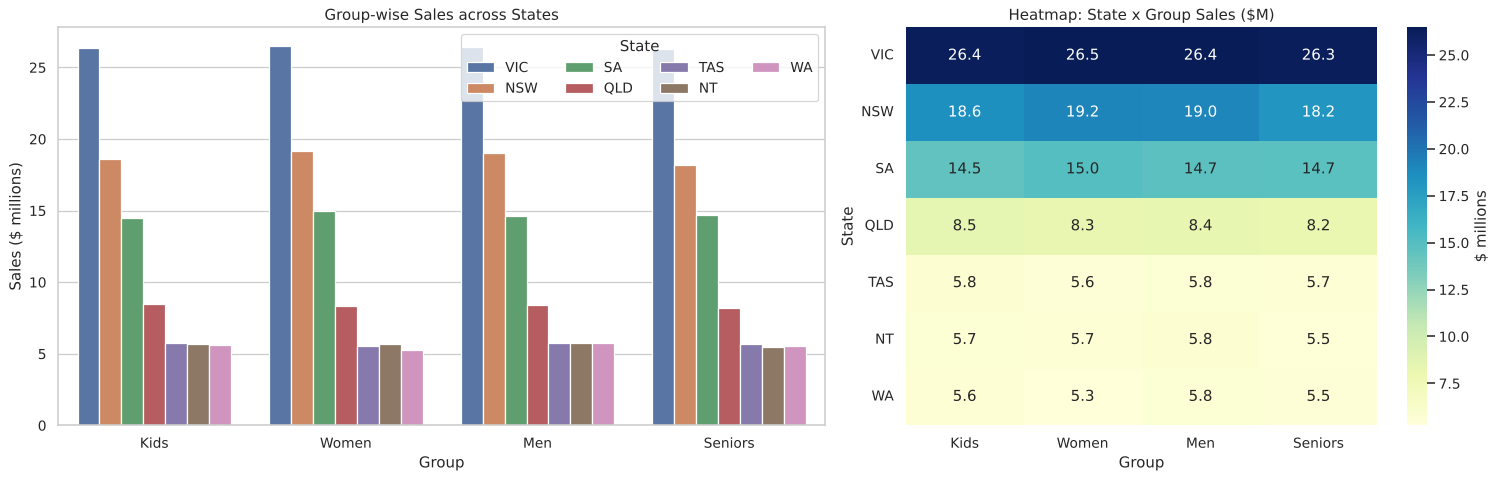

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw={"width_ratios": [1.3, 1]})
sns.barplot(data=plot_df, x="Group", y="Sales_M", hue="State", order=group_order, hue_order=state_order, ax=axes[0])
axes[0].set(title="Group-wise Sales across States", xlabel="Group", ylabel="Sales ($ millions)")
axes[0].legend(title="State", ncol=4)

heat = plot_df.pivot(index="State", columns="Group", values="Sales_M").loc[state_order, group_order]
sns.heatmap(heat, annot=True, fmt=".1f", cmap="YlGnBu", ax=axes[1], cbar_kws={"label": "$ millions"})
axes[1].set_title("Heatmap: State x Group Sales ($M)")
axes[1].tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()

## 3A. Time-of-day analysis: peak and off-peak periods

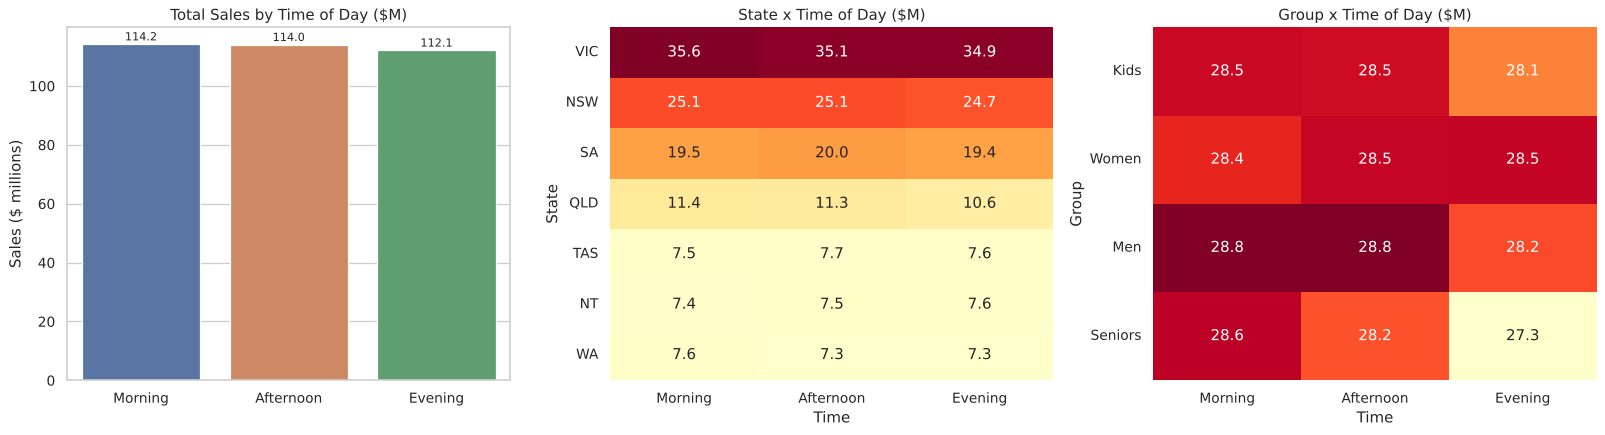

In [ ]:
time_total = df_clean.groupby("Time")["Sales"].sum().reindex(time_order) / 1e6
heat_ts = (df_clean.pivot_table(index="State", columns="Time", values="Sales", aggfunc="sum")[time_order]
           .loc[state_order] / 1e6)
heat_tg = (df_clean.pivot_table(index="Group", columns="Time", values="Sales", aggfunc="sum")[time_order]
           .loc[group_order] / 1e6)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.barplot(x=time_total.index, y=time_total.values, ax=axes[0], hue=time_total.index, legend=False)
label_bars(axes[0], "{:.1f}")
axes[0].set(title="Total Sales by Time of Day ($M)", xlabel="", ylabel="Sales ($ millions)")
sns.heatmap(heat_ts, annot=True, fmt=".1f", cmap="YlOrRd", ax=axes[1], cbar=False)
axes[1].set_title("State x Time of Day ($M)")
sns.heatmap(heat_tg, annot=True, fmt=".1f", cmap="YlOrRd", ax=axes[2], cbar=False)
axes[2].set_title("Group x Time of Day ($M)")
for ax in axes[1:]:
    ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()

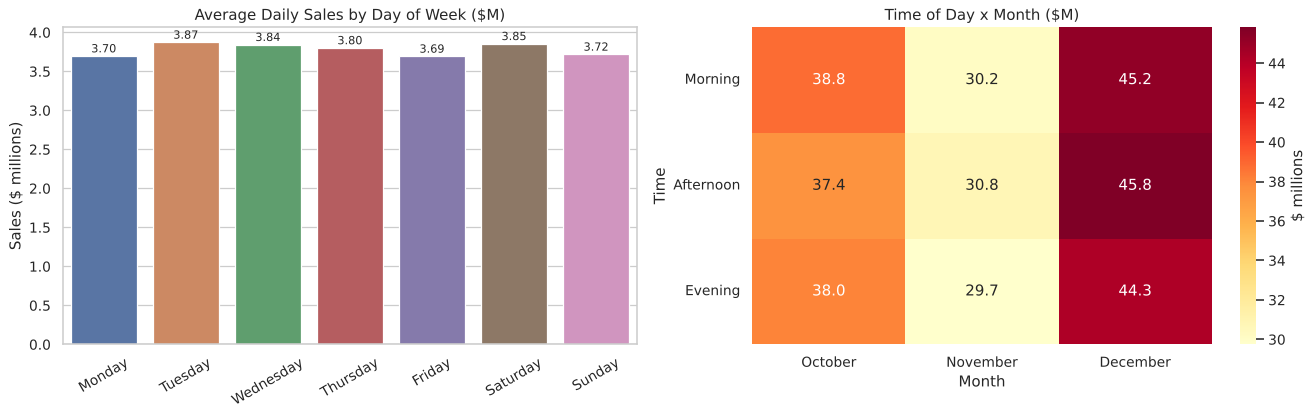

In [ ]:
# Day-of-week pattern (average sales per day, so unequal day counts do not bias the result)
daily_df = df_clean.groupby("Date", as_index=False)["Sales"].sum()
daily_df["DayName"] = daily_df["Date"].dt.day_name()
dow_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
dow_avg = daily_df.groupby("DayName")["Sales"].mean().reindex(dow_order) / 1e6

month_time = (df_clean.pivot_table(index="Time", columns="Month", values="Sales", aggfunc="sum")
              .loc[time_order, month_order] / 1e6)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
sns.barplot(x=dow_avg.index, y=dow_avg.values, ax=axes[0], hue=dow_avg.index, legend=False)
label_bars(axes[0], "{:.2f}")
axes[0].set(title="Average Daily Sales by Day of Week ($M)", xlabel="", ylabel="Sales ($ millions)")
axes[0].tick_params(axis="x", rotation=30)
sns.heatmap(month_time, annot=True, fmt=".1f", cmap="YlOrRd", ax=axes[1], cbar_kws={"label": "$ millions"})
axes[1].set_title("Time of Day x Month ($M)")
axes[1].tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()

## 3B. Daily, weekly, monthly and quarterly charts

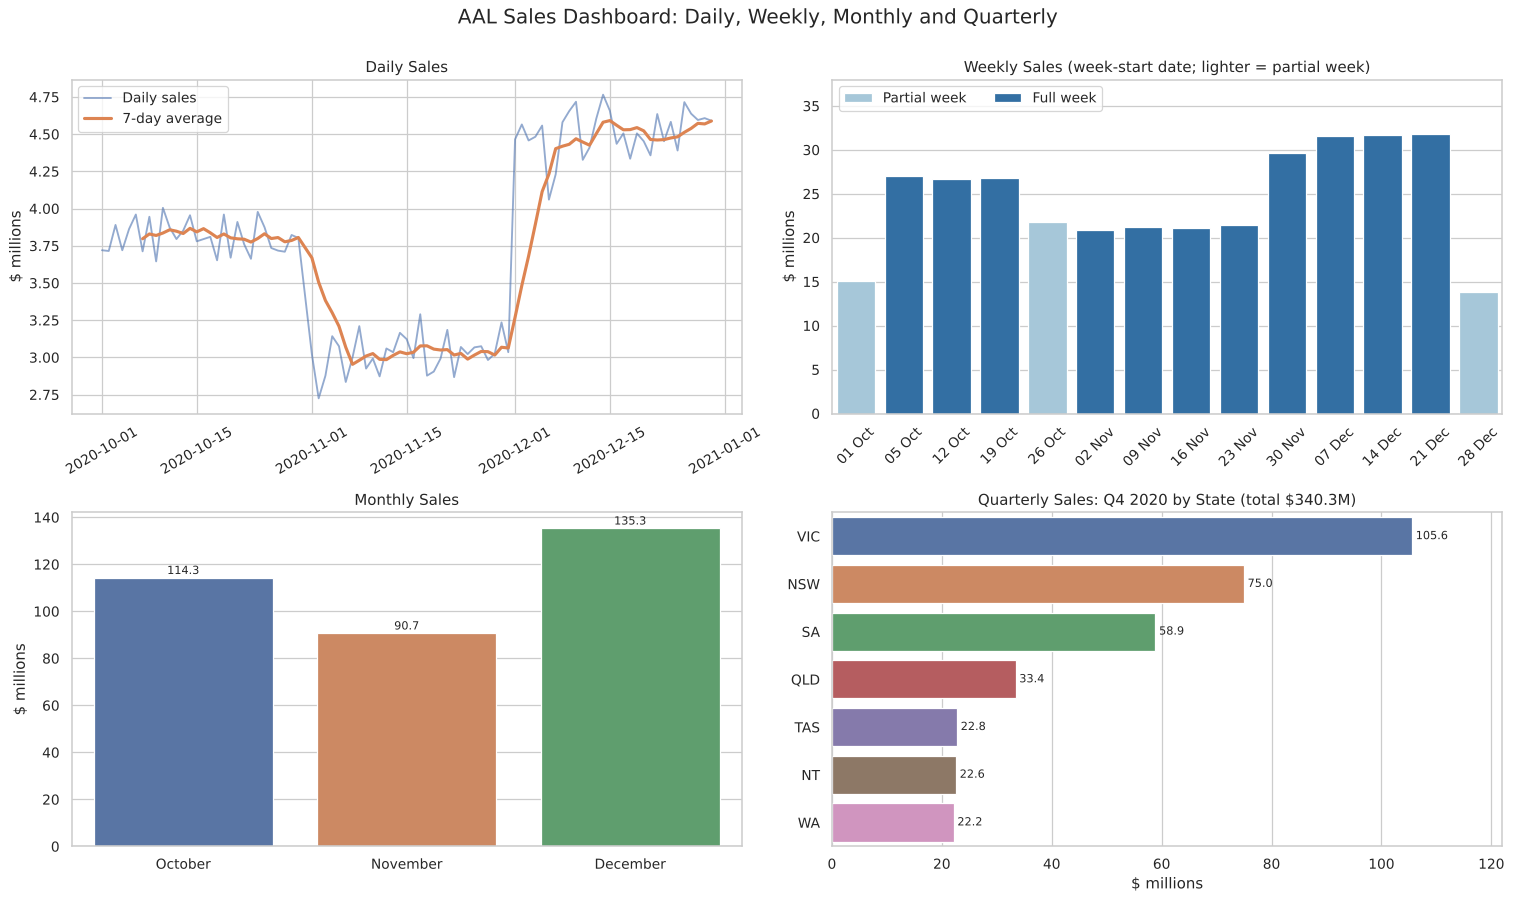

In [ ]:
daily_m = df_clean.groupby("Date")["Sales"].sum() / 1e6
weekly_m = weekly.copy()
weekly_m["Label"] = weekly_m["Week_Start"].dt.strftime("%d %b")
weekly_m["Sales_M"] = weekly_m["Total_Sales"] / 1e6
weekly_m["Type"] = np.where(weekly_m["Days"] < 7, "Partial week", "Full week")
monthly_m = (monthly["Total_Sales"] / 1e6).reset_index()
q_state_m = (q_state["Q4_Sales"] / 1e6).reset_index()

fig, axes = plt.subplots(2, 2, figsize=(17, 10))

# Daily
sns.lineplot(x=daily_m.index, y=daily_m.values, ax=axes[0, 0], label="Daily sales", alpha=0.6)
sns.lineplot(x=daily_m.index, y=daily_m.rolling(7).mean().values, ax=axes[0, 0], label="7-day average", linewidth=2.5)
axes[0, 0].set(title="Daily Sales", xlabel="", ylabel="$ millions")
axes[0, 0].tick_params(axis="x", rotation=30)

# Weekly
sns.barplot(data=weekly_m, x="Label", y="Sales_M", hue="Type", dodge=False,
            palette={"Full week": "#2171b5", "Partial week": "#9ecae1"}, ax=axes[0, 1])
axes[0, 1].set(title="Weekly Sales (week-start date; lighter = partial week)", xlabel="", ylabel="$ millions")
axes[0, 1].tick_params(axis="x", rotation=45)
axes[0, 1].set_ylim(0, 38)
axes[0, 1].legend(loc="upper left", ncol=2, title=None)

# Monthly
sns.barplot(data=monthly_m, x="Month", y="Total_Sales", hue="Month", legend=False, ax=axes[1, 0])
label_bars(axes[1, 0], "{:.1f}")
axes[1, 0].set(title="Monthly Sales", xlabel="", ylabel="$ millions")

# Quarterly (Q4 2020 by state)
sns.barplot(data=q_state_m, y="State", x="Q4_Sales", hue="State", legend=False, ax=axes[1, 1])
label_bars(axes[1, 1], "{:.1f}", horizontal=True)
axes[1, 1].set_xlim(0, 122)
axes[1, 1].set(title=f"Quarterly Sales: Q4 2020 by State (total ${daily_m.sum():,.1f}M)", xlabel="$ millions", ylabel="")

plt.suptitle("AAL Sales Dashboard: Daily, Weekly, Monthly and Quarterly", fontsize=16, y=1.0)
plt.tight_layout()
plt.show()

## 3B. Distribution plots (Seaborn)

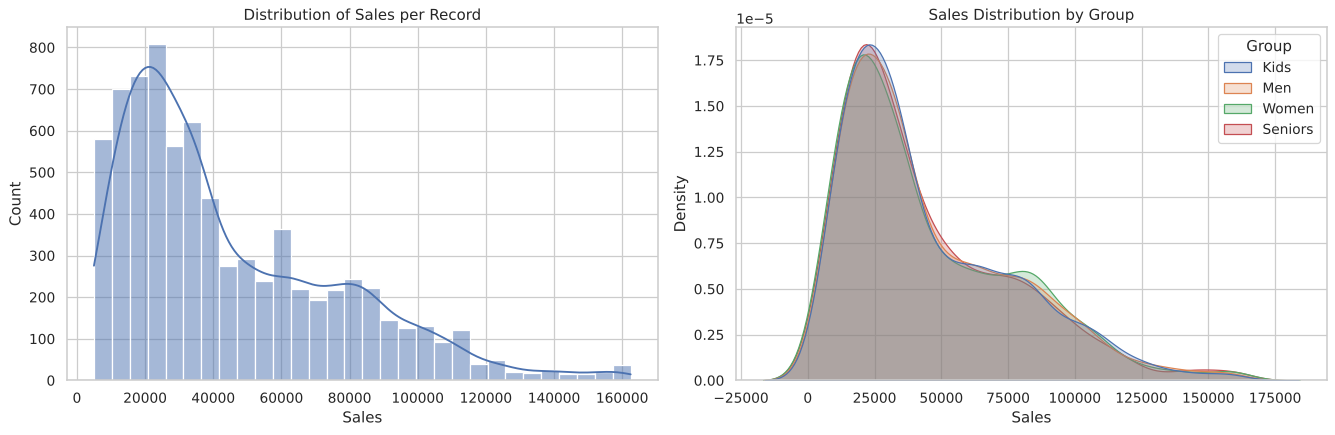

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(data=df_clean, x="Sales", bins=30, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Sales per Record")
sns.kdeplot(data=df_clean, x="Sales", hue="Group", fill=True, common_norm=False, alpha=0.25, ax=axes[1])
axes[1].set_title("Sales Distribution by Group")
plt.tight_layout()
plt.show()

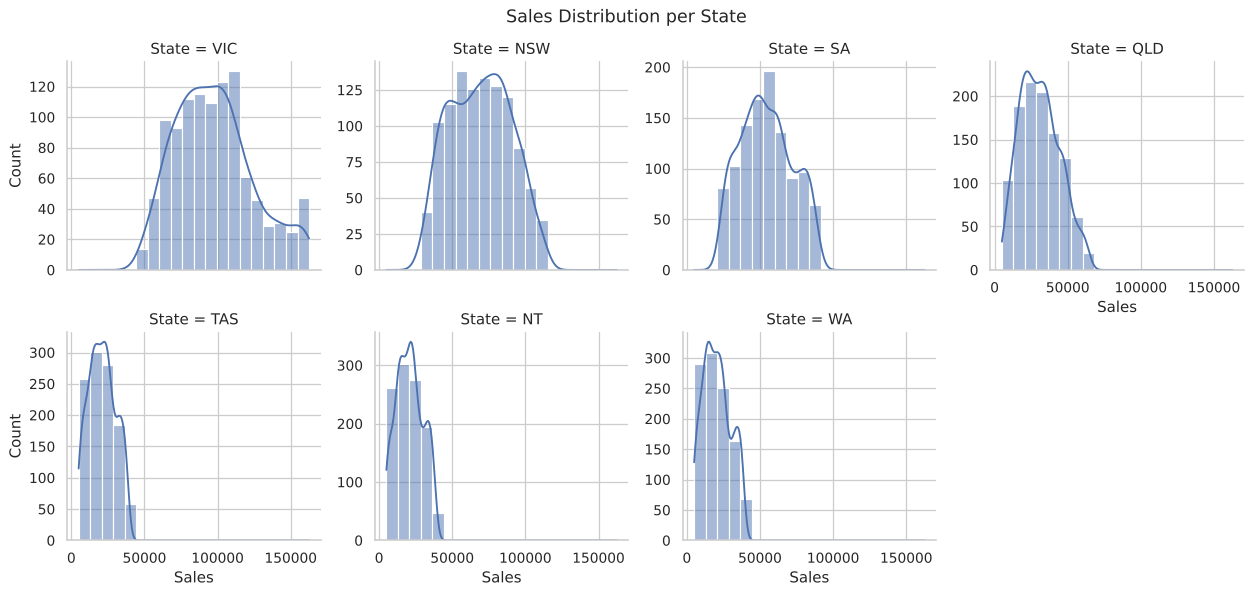

In [ ]:
# Distribution of Sales per record in each State
g = sns.displot(data=df_clean, x="Sales", col="State", col_order=state_order, col_wrap=4,
                kde=True, bins=20, height=3.2, aspect=1.1, facet_kws={"sharey": False})
g.fig.suptitle("Sales Distribution per State", y=1.03, fontsize=14)
plt.show()

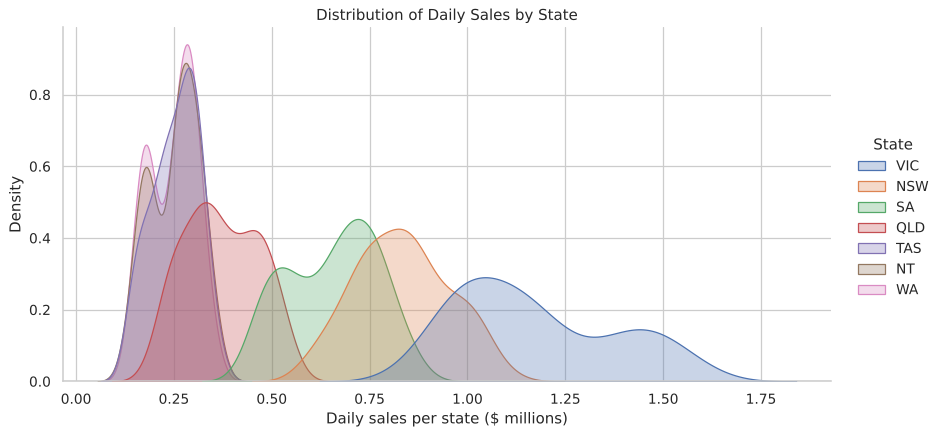

In [ ]:
# Distribution of DAILY sales per state: how far apart are the states?
daily_state = df_clean.groupby(["Date", "State"], as_index=False)["Sales"].sum()
daily_state["Sales_M"] = daily_state["Sales"] / 1e6
g = sns.displot(data=daily_state, x="Sales_M", hue="State", hue_order=state_order, kind="kde",
                fill=True, alpha=0.3, height=4.8, aspect=2)
g.set(xlabel="Daily sales per state ($ millions)", title="Distribution of Daily Sales by State")
plt.show()

## C. Recommended visualization package and why

# Step 4: Report
**Summary:** Cleaned the data (stripped stray spaces, parsed dates), normalized Unit and Sales, and analysed Q4 2020 sales by state, group, time of day and period. VIC, NSW and SA generate 70.3% of the $340.3M total while WA, NT and TAS are lowest, so target them with group-specific, volume-led offers and November promotions.